【エクスポートデータ】 ・violin_all.svg：PCスコアのグループ別分布図（画像）
。 ・PrincipalAxes_PCn.svg：各主成分に寄与する上位タンパク質のグラフ（画像）
。 

# Import library

In [1]:
#Initial setup
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

import pandas as pd
import os
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from decimal import Decimal, ROUND_HALF_UP
import matplotlib.pyplot as plt
import seaborn as sns

# Import datasets

In [2]:
fileDir = './Data/'
fileName = 'DataForRegression.csv'
# PancreasProject/Data/DataForRegression.csv
tempDF = pd.read_csv(fileDir + fileName)
tempDF = tempDF.set_index(tempDF.columns[0])
tempDF.index.name = None
display(tempDF)
display(tempDF.describe(include='all'))

pca_data = tempDF

,PC1 (19.9%),PC2 (7.0%),PC3 (3.8%),PC4 (3.4%),PC5 (2.4%),PC6 (2.2%),PC7 (1.7%),PC8 (1.4%),PC9 (1.3%),PC10 (1.1%),...,PC250 (0.1%),PC251 (0.1%),PC252 (0.1%),PC253 (0.1%),PC254 (0.1%),PC255 (0.1%),PC256 (0.1%),PC257 (0.1%),PC258 (0.1%),PC259 (0.1%)
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


,PC1 (19.9%),PC2 (7.0%),PC3 (3.8%),PC4 (3.4%),PC5 (2.4%),PC6 (2.2%),PC7 (1.7%),PC8 (1.4%),PC9 (1.3%),PC10 (1.1%),...,PC250 (0.1%),PC251 (0.1%),PC252 (0.1%),PC253 (0.1%),PC254 (0.1%),PC255 (0.1%),PC256 (0.1%),PC257 (0.1%),PC258 (0.1%),PC259 (0.1%)
count,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,...,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,398.000000,3.980000e+02,3.980000e+02
mean,5.712906e-16,7.141133e-17,1.785283e-17,2.499397e-16,-1.071170e-16,7.141133e-17,-3.570567e-17,1.785283e-17,-3.570567e-17,4.463208e-17,...,1.227382e-17,-4.909529e-17,4.574788e-17,-1.562123e-17,2.677925e-17,2.231604e-17,-3.124246e-17,0.000000,1.004222e-17,-8.926416e-18
std,1.437948e+01,8.497949e+00,6.259899e+00,5.904815e+00,4.963187e+00,4.757023e+00,4.177342e+00,3.839139e+00,3.735517e+00,3.447219e+00,...,8.242827e-01,8.227165e-01,8.200357e-01,8.162502e-01,8.087023e-01,8.063115e-01,7.945541e-01,0.793658,7.900064e-01,7.880754e-01
min,-2.711635e+01,-2.629658e+01,-1.668219e+01,-1.698651e+01,-1.455002e+01,-1.405542e+01,-1.096862e+01,-1.130787e+01,-1.186045e+01,-8.757062e+00,...,-2.471249e+00,-2.543121e+00,-2.137923e+00,-2.634246e+00,-2.330016e+00,-2.361457e+00,-2.471270e+00,-2.066688,-2.331782e+00,-2.581984e+00
25%,-9.358061e+00,-5.267991e+00,-4.268379e+00,-3.316688e+00,-3.367194e+00,-2.697410e+00,-2.966586e+00,-2.470633e+00,-2.424165e+00,-2.234652e+00,...,-4.701661e-01,-5.130118e-01,-5.406093e-01,-4.591096e-01,-5.088443e-01,-5.561077e-01,-4.538436e-01,-0.523605,-4.946316e-01,-5.302820e-01
50%,-2.902832e+00,3.796802e-02,-9.272805e-04,-3.387693e-01,-5.183615e-01,-2.951134e-02,-5.098784e-02,-2.486057e-01,-1.922131e-01,-1.219436e-01,...,3.143556e-02,3.826649e-02,5.398880e-02,7.067323e-02,-1.631901e-02,-3.712911e-02,7.984785e-03,-0.039082,-5.312299e-02,-1.260867e-02
75%,6.769484e+00,4.596052e+00,4.263626e+00,2.625137e+00,3.290777e+00,2.235187e+00,2.900097e+00,2.265234e+00,2.228297e+00,2.135437e+00,...,5.481562e-01,5.523407e-01,5.065511e-01,5.523370e-01,5.440846e-01,5.132725e-01,4.656954e-01,0.502430,5.070006e-01,5.096543e-01
max,6.505593e+01,2.788149e+01,2.469381e+01,3.355831e+01,1.780996e+01,2.436114e+01,1.447239e+01,2.782066e+01,1.558460e+01,1.175876e+01,...,2.631017e+00,2.599814e+00,2.542172e+00,2.817259e+00,3.164918e+00,2.438367e+00,2.533927e+00,2.134593,2.433389e+00,2.726829e+00


In [3]:
fileDir = "./Data/"
fileName = "pro_sample.csv"

path = os.path.join(fileDir, fileName)
sample = pd.read_csv(path)
sample.set_index(sample.columns[0],inplace=True)
sample.index.name = None
display(sample)

,progress,sex,fvage,CaCo_Status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R
PE_R478_001,0,1,58,0,NaN,NaN,2,8,1,25,20,0,4.100,134.0
PE_R478_002,0,1,62,0,NaN,NaN,2,10,1,33,23,0,1.999,5500.0
PE_R478_003,0,1,68,0,NaN,NaN,1,24,3,0,22,0,2.700,259.0
PE_R478_004,0,2,70,0,NaN,NaN,3,0,3,0,26,0,3.800,208.0
PE_R478_005,440,1,59,1,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,410,1,63,1,C250,84533.0,1,27,3,0,26,1,1.999,263.0
PE_R478_397,410,2,64,1,C250,85003.0,3,0,1,12,22,0,1.999,257.0
PE_R478_398,0,1,38,0,NaN,NaN,2,13,1,4,29,0,2.100,257.0
PE_R478_399,410,2,47,1,C250,85003.0,3,0,1,2,21,0,16.900,216.0


In [4]:
fileDir = "./Data/"
fileName = "map_OID_Uni_Sym.csv"

path = os.path.join(fileDir, fileName)
IDdata = pd.read_csv(path)
IDdata.set_index(IDdata.columns[0],inplace=True)
IDdata.index.name = None
display(IDdata)

,OlinkID,UniProt,Symbol
1,OID50001,AMP1,AMP1*
2,OID50002,INC1,INC1*
3,OID50003,EXT1,EXT1*
4,OID50004,P24385,CCND1
5,OID50005,Q8N2Z9,CENPS
...,...,...,...
1036,OID51099,Q15262,PTPRK
1037,OID51100,P25685,DNAJB1
1038,OID51101,Q9Y570,PPME1
1039,OID51102,Q6UB99,ANKRD11


In [5]:
fileDir = "./Data/"
fileName = "pcaDF_axes.csv"

path = os.path.join(fileDir, fileName)
pcaDF_axes = pd.read_csv(path)
pcaDF_axes.set_index(pcaDF_axes.columns[0],inplace=True)
pcaDF_axes.index.name = None
display(pcaDF_axes)

,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PC1,0.018141,-0.004737,0.021761,0.006063,0.041839,0.030468,0.006441,0.043154,0.017218,0.015853,...,0.039344,0.018985,0.012664,0.035853,0.031691,0.023250,0.040980,0.034978,0.009618,0.027507
PC2,-0.011992,0.010740,-0.003306,-0.009857,-0.043476,-0.009187,0.001369,-0.039104,-0.010706,-0.004135,...,-0.028666,-0.000839,-0.009036,-0.065866,0.020575,0.016238,-0.041701,-0.029594,-0.004091,-0.026546
PC3,-0.001035,-0.015287,-0.005925,0.023402,0.071158,0.019409,-0.004748,0.015814,0.012418,0.016363,...,-0.017275,0.003634,-0.019394,-0.077463,-0.005245,0.006774,0.016748,-0.014603,0.011661,-0.029670
PC4,-0.014467,0.011010,-0.004627,-0.013568,-0.027955,-0.014996,-0.020517,-0.004934,-0.008837,-0.003717,...,0.011654,0.005623,-0.019869,-0.014138,0.092737,0.004326,0.001004,-0.003687,-0.014803,0.006287
PC5,-0.057522,-0.016070,-0.049044,-0.018675,-0.022332,-0.045029,-0.021405,-0.017342,-0.021832,-0.000922,...,0.011160,-0.019369,-0.015369,0.028363,-0.029990,-0.036025,-0.013407,-0.005913,-0.030760,-0.023038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PC255,-0.046008,0.026657,0.043553,-0.095817,-0.032160,-0.011763,0.028164,0.013966,-0.010409,0.022412,...,0.015217,-0.008828,-0.031507,-0.005965,0.048988,-0.011612,0.022444,-0.035590,0.003275,0.030763
PC256,-0.021451,-0.057636,0.002539,0.006031,-0.019448,-0.020783,0.019314,-0.030096,-0.042540,0.052954,...,0.006478,-0.006066,-0.005593,0.001059,-0.012795,-0.028930,-0.031454,0.006893,-0.020728,0.029081
PC257,-0.020061,0.018352,0.063575,-0.027166,0.015082,-0.024189,-0.007664,0.051994,-0.043859,-0.033885,...,-0.046666,0.037734,0.020240,0.009389,-0.019547,-0.022127,0.032089,-0.043474,0.005664,0.005803
PC258,0.015700,0.015389,0.028041,0.055394,-0.010367,0.038182,0.039445,0.009034,0.043802,0.022032,...,-0.016742,-0.002900,0.010847,-0.014274,0.034153,0.038502,-0.017810,-0.013876,0.007142,-0.027913


In [6]:
fileDir = "./Data/"
fileName = "pca_varDF.csv"

path = os.path.join(fileDir, fileName)
pca_varDF = pd.read_csv(path)
pca_varDF.set_index(pca_varDF.columns[0],inplace=True)
pca_varDF.index.name = None
display(pca_varDF)

fileDir = "./Data/"
fileName = "pca_projDF.csv"

path = os.path.join(fileDir, fileName)
pca_projDF = pd.read_csv(path)
pca_projDF.set_index(pca_projDF.columns[0],inplace=True)
pca_projDF.index.name = None
display(pca_projDF)

,PCnumber,ExplainedVariance,PClabel
PC1,1,19.908293,PC1
PC2,2,6.953059,PC2
PC3,3,3.772961,PC3
PC4,4,3.357069,PC4
PC5,5,2.371750,PC5
...,...,...,...
PC255,255,0.062597,PC255
PC256,256,0.060785,PC256
PC257,257,0.060648,PC257
PC258,258,0.060091,PC258


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC250,PC251,PC252,PC253,PC254,PC255,PC256,PC257,PC258,PC259
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


## Delete % from column

In [7]:
tempDF = pca_data
print("before: ")
display(tempDF)

tempDF.columns = [col.split()[0] for col in tempDF.columns]
print("After: ")
display(tempDF)
pca_data = tempDF

before: 


,PC1 (19.9%),PC2 (7.0%),PC3 (3.8%),PC4 (3.4%),PC5 (2.4%),PC6 (2.2%),PC7 (1.7%),PC8 (1.4%),PC9 (1.3%),PC10 (1.1%),...,PC250 (0.1%),PC251 (0.1%),PC252 (0.1%),PC253 (0.1%),PC254 (0.1%),PC255 (0.1%),PC256 (0.1%),PC257 (0.1%),PC258 (0.1%),PC259 (0.1%)
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


After: 


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC250,PC251,PC252,PC253,PC254,PC255,PC256,PC257,PC258,PC259
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


In [8]:
tempDF = pca_projDF
print("before: ")
display(tempDF)

tempDF.columns = [col.split()[0] for col in tempDF.columns]
print("After: ")
display(tempDF)
pca_projDF = tempDF

before: 


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC250,PC251,PC252,PC253,PC254,PC255,PC256,PC257,PC258,PC259
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


After: 


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC250,PC251,PC252,PC253,PC254,PC255,PC256,PC257,PC258,PC259
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


In [9]:
tempDF = pcaDF_axes
print("before: ")
display(tempDF)

tempDF.index = [idx.split()[0] for idx in tempDF.index]
print("After: ")
display(tempDF)
pcaDF_axes = tempDF

before: 


,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PC1,0.018141,-0.004737,0.021761,0.006063,0.041839,0.030468,0.006441,0.043154,0.017218,0.015853,...,0.039344,0.018985,0.012664,0.035853,0.031691,0.023250,0.040980,0.034978,0.009618,0.027507
PC2,-0.011992,0.010740,-0.003306,-0.009857,-0.043476,-0.009187,0.001369,-0.039104,-0.010706,-0.004135,...,-0.028666,-0.000839,-0.009036,-0.065866,0.020575,0.016238,-0.041701,-0.029594,-0.004091,-0.026546
PC3,-0.001035,-0.015287,-0.005925,0.023402,0.071158,0.019409,-0.004748,0.015814,0.012418,0.016363,...,-0.017275,0.003634,-0.019394,-0.077463,-0.005245,0.006774,0.016748,-0.014603,0.011661,-0.029670
PC4,-0.014467,0.011010,-0.004627,-0.013568,-0.027955,-0.014996,-0.020517,-0.004934,-0.008837,-0.003717,...,0.011654,0.005623,-0.019869,-0.014138,0.092737,0.004326,0.001004,-0.003687,-0.014803,0.006287
PC5,-0.057522,-0.016070,-0.049044,-0.018675,-0.022332,-0.045029,-0.021405,-0.017342,-0.021832,-0.000922,...,0.011160,-0.019369,-0.015369,0.028363,-0.029990,-0.036025,-0.013407,-0.005913,-0.030760,-0.023038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PC255,-0.046008,0.026657,0.043553,-0.095817,-0.032160,-0.011763,0.028164,0.013966,-0.010409,0.022412,...,0.015217,-0.008828,-0.031507,-0.005965,0.048988,-0.011612,0.022444,-0.035590,0.003275,0.030763
PC256,-0.021451,-0.057636,0.002539,0.006031,-0.019448,-0.020783,0.019314,-0.030096,-0.042540,0.052954,...,0.006478,-0.006066,-0.005593,0.001059,-0.012795,-0.028930,-0.031454,0.006893,-0.020728,0.029081
PC257,-0.020061,0.018352,0.063575,-0.027166,0.015082,-0.024189,-0.007664,0.051994,-0.043859,-0.033885,...,-0.046666,0.037734,0.020240,0.009389,-0.019547,-0.022127,0.032089,-0.043474,0.005664,0.005803
PC258,0.015700,0.015389,0.028041,0.055394,-0.010367,0.038182,0.039445,0.009034,0.043802,0.022032,...,-0.016742,-0.002900,0.010847,-0.014274,0.034153,0.038502,-0.017810,-0.013876,0.007142,-0.027913


After: 


,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PC1,0.018141,-0.004737,0.021761,0.006063,0.041839,0.030468,0.006441,0.043154,0.017218,0.015853,...,0.039344,0.018985,0.012664,0.035853,0.031691,0.023250,0.040980,0.034978,0.009618,0.027507
PC2,-0.011992,0.010740,-0.003306,-0.009857,-0.043476,-0.009187,0.001369,-0.039104,-0.010706,-0.004135,...,-0.028666,-0.000839,-0.009036,-0.065866,0.020575,0.016238,-0.041701,-0.029594,-0.004091,-0.026546
PC3,-0.001035,-0.015287,-0.005925,0.023402,0.071158,0.019409,-0.004748,0.015814,0.012418,0.016363,...,-0.017275,0.003634,-0.019394,-0.077463,-0.005245,0.006774,0.016748,-0.014603,0.011661,-0.029670
PC4,-0.014467,0.011010,-0.004627,-0.013568,-0.027955,-0.014996,-0.020517,-0.004934,-0.008837,-0.003717,...,0.011654,0.005623,-0.019869,-0.014138,0.092737,0.004326,0.001004,-0.003687,-0.014803,0.006287
PC5,-0.057522,-0.016070,-0.049044,-0.018675,-0.022332,-0.045029,-0.021405,-0.017342,-0.021832,-0.000922,...,0.011160,-0.019369,-0.015369,0.028363,-0.029990,-0.036025,-0.013407,-0.005913,-0.030760,-0.023038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PC255,-0.046008,0.026657,0.043553,-0.095817,-0.032160,-0.011763,0.028164,0.013966,-0.010409,0.022412,...,0.015217,-0.008828,-0.031507,-0.005965,0.048988,-0.011612,0.022444,-0.035590,0.003275,0.030763
PC256,-0.021451,-0.057636,0.002539,0.006031,-0.019448,-0.020783,0.019314,-0.030096,-0.042540,0.052954,...,0.006478,-0.006066,-0.005593,0.001059,-0.012795,-0.028930,-0.031454,0.006893,-0.020728,0.029081
PC257,-0.020061,0.018352,0.063575,-0.027166,0.015082,-0.024189,-0.007664,0.051994,-0.043859,-0.033885,...,-0.046666,0.037734,0.020240,0.009389,-0.019547,-0.022127,0.032089,-0.043474,0.005664,0.005803
PC258,0.015700,0.015389,0.028041,0.055394,-0.010367,0.038182,0.039445,0.009034,0.043802,0.022032,...,-0.016742,-0.002900,0.010847,-0.014274,0.034153,0.038502,-0.017810,-0.013876,0.007142,-0.027913


# Select significant PCA

In [10]:
tempDF = pca_data
selected = ['PC21','PC1','PC4','PC7','PC5','PC10','PC6']
tempDF2 = tempDF[selected]
display(tempDF2)
selected_data = tempDF2

,PC21,PC1,PC4,PC7,PC5,PC10,PC6
PE_R478_001,-2.593913,-11.355640,0.986114,-1.813944,3.315245,0.364327,4.351226
PE_R478_002,12.480767,28.766284,7.497081,4.725005,10.382521,-5.800743,9.502187
PE_R478_003,2.888927,0.020907,-6.175430,-2.191429,2.122866,-0.717173,0.261548
PE_R478_004,-1.033515,1.280354,11.175303,-4.031425,-5.285951,-0.824243,2.919094
PE_R478_005,-8.984611,47.165163,13.197488,3.679527,4.967250,9.475449,-10.946485
...,...,...,...,...,...,...,...
PE_R478_396,4.796905,2.143146,6.833900,-3.193656,-11.311680,-2.905974,0.793727
PE_R478_397,-5.219433,38.061665,27.387240,2.291494,-11.711320,-1.006462,-3.291643
PE_R478_398,-1.218278,-14.914629,6.261250,-4.011564,-2.796122,2.105016,-0.106774
PE_R478_399,-1.040886,-3.590776,1.408932,6.327413,-2.785291,0.282851,-4.212388


## combine PCA data and sample data

In [11]:
merged_data = pd.concat([selected_data, sample], axis = 1)
display(merged_data)

,PC21,PC1,PC4,PC7,PC5,PC10,PC6,progress,sex,fvage,...,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R
PE_R478_001,-2.593913,-11.355640,0.986114,-1.813944,3.315245,0.364327,4.351226,0,1,58,...,NaN,NaN,2,8,1,25,20,0,4.100,134.0
PE_R478_002,12.480767,28.766284,7.497081,4.725005,10.382521,-5.800743,9.502187,0,1,62,...,NaN,NaN,2,10,1,33,23,0,1.999,5500.0
PE_R478_003,2.888927,0.020907,-6.175430,-2.191429,2.122866,-0.717173,0.261548,0,1,68,...,NaN,NaN,1,24,3,0,22,0,2.700,259.0
PE_R478_004,-1.033515,1.280354,11.175303,-4.031425,-5.285951,-0.824243,2.919094,0,2,70,...,NaN,NaN,3,0,3,0,26,0,3.800,208.0
PE_R478_005,-8.984611,47.165163,13.197488,3.679527,4.967250,9.475449,-10.946485,440,1,59,...,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,4.796905,2.143146,6.833900,-3.193656,-11.311680,-2.905974,0.793727,410,1,63,...,C250,84533.0,1,27,3,0,26,1,1.999,263.0
PE_R478_397,-5.219433,38.061665,27.387240,2.291494,-11.711320,-1.006462,-3.291643,410,2,64,...,C250,85003.0,3,0,1,12,22,0,1.999,257.0
PE_R478_398,-1.218278,-14.914629,6.261250,-4.011564,-2.796122,2.105016,-0.106774,0,1,38,...,NaN,NaN,2,13,1,4,29,0,2.100,257.0
PE_R478_399,-1.040886,-3.590776,1.408932,6.327413,-2.785291,0.282851,-4.212388,410,2,47,...,C250,85003.0,3,0,1,2,21,0,16.900,216.0


# Visualization (Violin plot)

## Groupset2(cancer or not)

<Figure size 400x300 with 0 Axes>

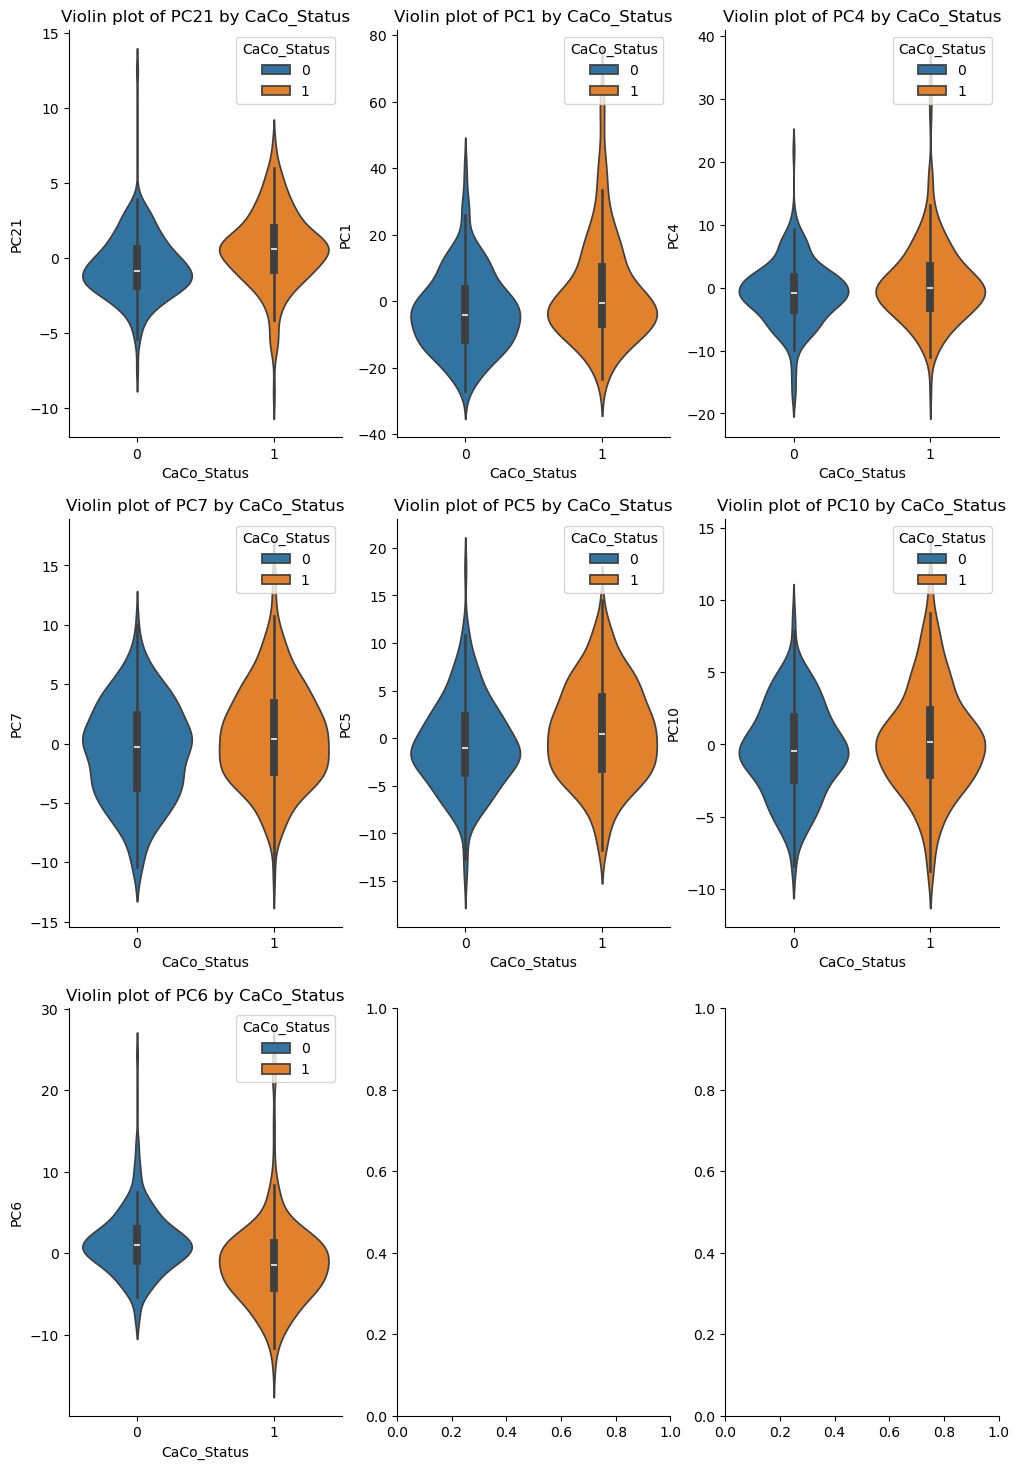

In [12]:
#Visualization: violinplots per feature
classname = 'CaCo_Status'
tempDF = merged_data

plt.figure(figsize=(4, 3))
columns_plot = [col for col in tempDF.columns[:7]]

n_cols = 3
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.violinplot(data=tempDF, x=classname, y=column, hue=classname,
                  ax = axes[column_index], palette = 'tab10')
    axes[column_index].set_title(f'Violin plot of {column} by {classname}')
sns.despine()
plt.show()
fig.savefig("./ExportData/violin_all.svg",dpi = 300, bbox_inches="tight",transparent=True)


# Principal axes

In [13]:
display(pcaDF_axes)
display(pca_varDF)
display(IDdata)

,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PC1,0.018141,-0.004737,0.021761,0.006063,0.041839,0.030468,0.006441,0.043154,0.017218,0.015853,...,0.039344,0.018985,0.012664,0.035853,0.031691,0.023250,0.040980,0.034978,0.009618,0.027507
PC2,-0.011992,0.010740,-0.003306,-0.009857,-0.043476,-0.009187,0.001369,-0.039104,-0.010706,-0.004135,...,-0.028666,-0.000839,-0.009036,-0.065866,0.020575,0.016238,-0.041701,-0.029594,-0.004091,-0.026546
PC3,-0.001035,-0.015287,-0.005925,0.023402,0.071158,0.019409,-0.004748,0.015814,0.012418,0.016363,...,-0.017275,0.003634,-0.019394,-0.077463,-0.005245,0.006774,0.016748,-0.014603,0.011661,-0.029670
PC4,-0.014467,0.011010,-0.004627,-0.013568,-0.027955,-0.014996,-0.020517,-0.004934,-0.008837,-0.003717,...,0.011654,0.005623,-0.019869,-0.014138,0.092737,0.004326,0.001004,-0.003687,-0.014803,0.006287
PC5,-0.057522,-0.016070,-0.049044,-0.018675,-0.022332,-0.045029,-0.021405,-0.017342,-0.021832,-0.000922,...,0.011160,-0.019369,-0.015369,0.028363,-0.029990,-0.036025,-0.013407,-0.005913,-0.030760,-0.023038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PC255,-0.046008,0.026657,0.043553,-0.095817,-0.032160,-0.011763,0.028164,0.013966,-0.010409,0.022412,...,0.015217,-0.008828,-0.031507,-0.005965,0.048988,-0.011612,0.022444,-0.035590,0.003275,0.030763
PC256,-0.021451,-0.057636,0.002539,0.006031,-0.019448,-0.020783,0.019314,-0.030096,-0.042540,0.052954,...,0.006478,-0.006066,-0.005593,0.001059,-0.012795,-0.028930,-0.031454,0.006893,-0.020728,0.029081
PC257,-0.020061,0.018352,0.063575,-0.027166,0.015082,-0.024189,-0.007664,0.051994,-0.043859,-0.033885,...,-0.046666,0.037734,0.020240,0.009389,-0.019547,-0.022127,0.032089,-0.043474,0.005664,0.005803
PC258,0.015700,0.015389,0.028041,0.055394,-0.010367,0.038182,0.039445,0.009034,0.043802,0.022032,...,-0.016742,-0.002900,0.010847,-0.014274,0.034153,0.038502,-0.017810,-0.013876,0.007142,-0.027913


,PCnumber,ExplainedVariance,PClabel
PC1,1,19.908293,PC1
PC2,2,6.953059,PC2
PC3,3,3.772961,PC3
PC4,4,3.357069,PC4
PC5,5,2.371750,PC5
...,...,...,...
PC255,255,0.062597,PC255
PC256,256,0.060785,PC256
PC257,257,0.060648,PC257
PC258,258,0.060091,PC258


,OlinkID,UniProt,Symbol
1,OID50001,AMP1,AMP1*
2,OID50002,INC1,INC1*
3,OID50003,EXT1,EXT1*
4,OID50004,P24385,CCND1
5,OID50005,Q8N2Z9,CENPS
...,...,...,...
1036,OID51099,Q15262,PTPRK
1037,OID51100,P25685,DNAJB1
1038,OID51101,Q9Y570,PPME1
1039,OID51102,Q6UB99,ANKRD11


,PC21,PC1,PC4,PC7,PC5,PC10,PC6
Symbol,,,,,,,
AMP1*,-0.011586,0.018141,-0.014467,-0.015036,-0.057522,0.087969,-0.024905
INC1*,0.014927,-0.004737,0.011010,0.005368,-0.016070,-0.055952,0.030074
CCND1,0.023978,0.021761,-0.004627,-0.019611,-0.049044,0.035136,-0.008352
CENPS,-0.015819,0.006063,-0.013568,0.007379,-0.018675,0.008606,0.006722
ERG,-0.061130,0.041839,-0.027955,0.031332,-0.022332,-0.005652,-0.018276
...,...,...,...,...,...,...,...
PTPRK,0.041745,0.023250,0.004326,-0.014785,-0.036025,0.047343,-0.010078
DNAJB1,-0.018825,0.040980,0.001004,0.018674,-0.013407,0.036586,0.097203
PPME1,-0.006872,0.034978,-0.003687,0.046334,-0.005913,0.075362,0.120998


Top 30 contributors in PC21


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC21_abs
Symbol,,,,,,,,
CTRL,0.130882,0.009735,0.031935,0.055914,0.000172,0.022106,-0.023938,0.130882
SERPINI2,0.127397,0.005975,0.036571,0.037419,-0.015934,0.018984,-0.007040,0.127397
GP2,0.116463,0.013856,0.032943,0.065155,0.014950,0.011156,-0.012733,0.116463
LCK,0.114799,0.027322,-0.026734,-0.080798,-0.058129,0.005313,0.019469,0.114799
CTRC,0.112067,0.002825,0.023572,0.034674,-0.035220,0.011188,-0.002722,0.112067
MMP12,0.103359,0.033823,-0.001044,-0.021524,0.043397,0.003149,-0.035443,0.103359
KRT19,0.100874,0.033610,0.014336,0.048021,0.044295,0.076486,-0.060570,0.100874
PNLIPRP1,0.099647,0.013638,0.035200,0.015654,0.023274,0.015840,0.000497,0.099647
IFIT3,-0.099191,0.037037,-0.020663,-0.005801,-0.021852,-0.080444,-0.036380,0.099191


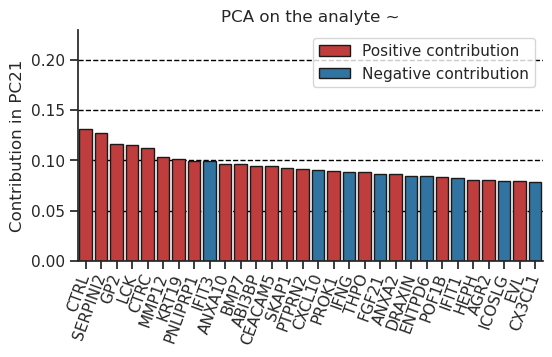

Top 30 contributors in PC1


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC1_abs
Symbol,,,,,,,,
PAG1,0.011360,0.061442,-0.012053,0.022850,0.014229,-0.017938,-0.020515,0.061442
RC3H1,0.020314,0.060743,0.027652,-0.002012,0.004524,-0.007177,-0.014082,0.060743
TXLNA,0.040927,0.060689,0.014615,-0.021164,-0.009806,-0.016683,0.032458,0.060689
MAD1L1,0.010535,0.060090,0.028914,0.021029,0.042565,0.000247,-0.033787,0.060090
MAP2K1,-0.006116,0.059407,-0.007628,0.029909,0.014956,-0.009947,0.018928,0.059407
POLR2F,0.009300,0.059211,-0.002443,0.012247,0.015757,0.017328,-0.007971,0.059211
USO1,-0.006515,0.059013,0.023324,0.018069,-0.014995,-0.003480,0.018948,0.059013
PRKAR2A,-0.008726,0.058787,0.046720,0.012332,-0.002926,-0.014325,0.019122,0.058787
CASP8,-0.001832,0.058624,-0.015682,0.008898,0.007541,0.009019,0.012053,0.058624


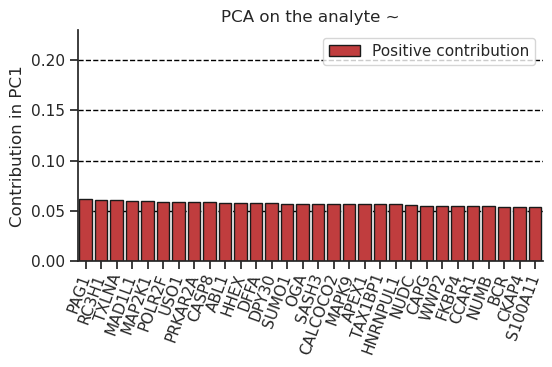

Top 30 contributors in PC4


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC4_abs
Symbol,,,,,,,,
PDZK1,-0.037252,0.040046,0.103831,-0.018275,-0.032622,-0.031703,0.008182,0.103831
BAIAP2,0.061297,0.034036,0.100999,-0.019314,-0.027263,-0.006484,-0.011034,0.100999
SULT2A1,-0.000198,0.035899,0.099465,-0.047157,-0.025651,-0.013823,0.004594,0.099465
ACAA1,0.016752,0.035255,0.099044,-0.005055,-0.037796,-0.059854,0.011695,0.099044
SPATA2L,0.013949,0.030014,0.098128,-0.019024,-0.039193,-0.047193,0.012684,0.098128
ACE2,-0.030890,0.037926,0.097755,0.006000,-0.003638,-0.001273,0.004920,0.097755
GFER,-0.005059,0.041326,0.097411,-0.031280,-0.025929,-0.039310,0.007493,0.097411
HAO1,0.011270,0.026835,0.093226,-0.030666,-0.053386,-0.043731,0.014169,0.093226
KHK,-0.003397,0.029567,0.092921,-0.064530,-0.057108,-0.037599,0.018690,0.092921


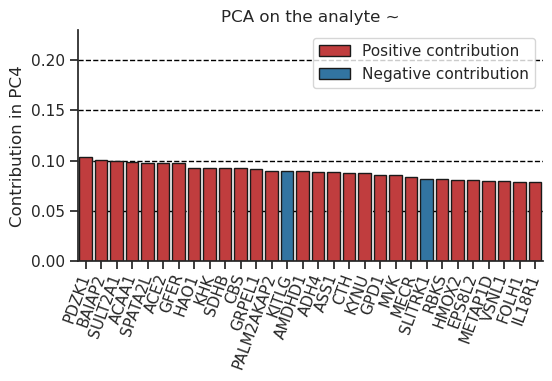

Top 30 contributors in PC7


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC7_abs
Symbol,,,,,,,,
MS4A1,0.030863,0.012027,-0.005891,-0.104177,-0.061747,0.001376,-0.015191,0.104177
FURIN,-0.013547,0.024370,0.009313,-0.102321,-0.036944,0.045169,-0.024999,0.102321
HBEGF,0.013015,0.009697,0.008611,-0.099379,-0.013257,0.103344,-0.031302,0.099379
IFNLR1,0.003543,0.028544,0.000201,-0.098871,-0.027391,0.023372,-0.015119,0.098871
BACE1,0.004440,-0.000599,-0.051780,0.091711,-0.104687,-0.004121,-0.003629,0.091711
SIT1,0.058159,0.020864,0.011803,-0.091250,-0.072778,-0.017933,0.005705,0.091250
BCAN,0.006055,0.001604,-0.058145,0.088370,-0.057374,0.000023,-0.016025,0.088370
PGLYRP3,0.032332,0.001282,-0.023137,-0.086696,-0.018951,0.013415,0.060675,0.086696
NPPC,0.043480,0.013365,-0.037345,-0.086695,0.005004,0.052675,0.029202,0.086695


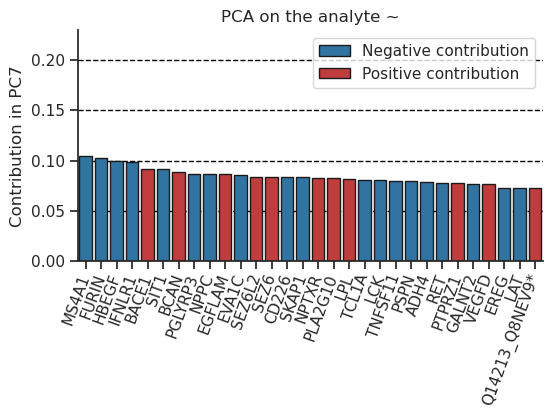

Top 30 contributors in PC5


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC5_abs
Symbol,,,,,,,,
ROBO2,0.015712,-0.001564,-0.058648,0.038611,-0.104994,-0.009796,-0.010759,0.104994
BACE1,0.004440,-0.000599,-0.051780,0.091711,-0.104687,-0.004121,-0.003629,0.104687
ENPP6,0.013627,-0.015691,-0.046354,0.045779,-0.103495,-0.026507,0.007445,0.103495
C1QL2,-0.007343,-0.005063,-0.025471,-0.027635,-0.102179,-0.003062,-0.035217,0.102179
RECK,-0.037800,0.005157,-0.035175,0.049903,-0.100884,-0.010694,-0.035610,0.100884
CD22,-0.007100,0.009903,-0.008951,-0.057418,-0.094818,-0.008491,-0.026342,0.094818
NELL1,0.036296,-0.000533,0.002500,0.037441,-0.093481,0.006015,-0.005447,0.093481
PTPRZ1,-0.003174,0.002189,-0.041059,0.077294,-0.091570,-0.050472,-0.017581,0.091570
NPHS1,0.017770,0.002013,0.000742,-0.021029,-0.089904,0.019163,-0.021944,0.089904


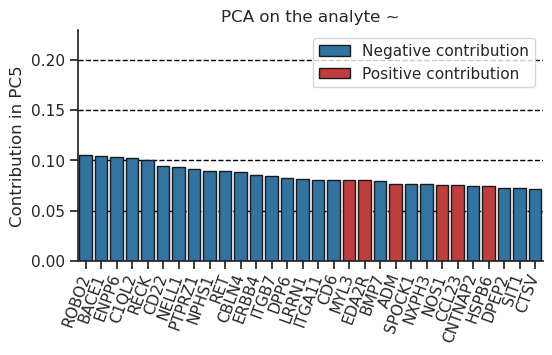

Top 30 contributors in PC10


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC10_abs
Symbol,,,,,,,,
IL7,-0.005077,0.014038,0.011883,-0.038208,-0.011986,0.116065,-0.046795,0.116065
ADAM12,0.008934,0.032563,-0.000474,-0.004677,0.032332,0.109990,-0.052740,0.109990
PAEP,0.016104,0.015588,0.008359,0.034390,0.030263,0.105539,-0.055555,0.105539
HBEGF,0.013015,0.009697,0.008611,-0.099379,-0.013257,0.103344,-0.031302,0.103344
COL24A1,0.045090,0.019244,-0.024818,0.004406,-0.013746,0.097779,-0.068056,0.097779
ITGAV,-0.059654,-0.010738,-0.022434,0.022798,-0.058218,-0.092301,0.029438,0.092301
LAT,-0.018785,0.017084,0.003037,-0.072902,-0.006321,0.089896,-0.005588,0.089896
AMP1*,-0.011586,0.018141,-0.014467,-0.015036,-0.057522,0.087969,-0.024905,0.087969
AMIGO2,0.011649,0.035418,0.016179,0.011982,-0.046208,0.087239,-0.054350,0.087239


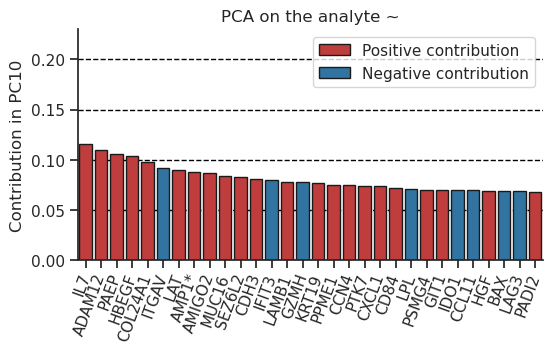

Top 30 contributors in PC6


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC6_abs
Symbol,,,,,,,,
UBAC1,0.009259,0.025633,-0.002213,0.056372,-0.009510,0.040382,0.152999,0.152999
HMBS,-0.004925,0.023815,0.011633,0.040976,-0.020890,0.062321,0.151246,0.151246
RILP,-0.012579,0.030322,0.013457,0.054598,-0.022945,0.059772,0.143551,0.143551
GMPR,-0.005595,0.016991,-0.007202,0.034976,-0.023610,0.049324,0.140720,0.140720
C9orf40,-0.031078,0.018382,-0.003735,0.032031,-0.036460,0.066745,0.136713,0.136713
RAB3IL1,-0.020238,0.030289,0.021567,0.046278,-0.010985,0.057842,0.131640,0.131640
DNAJA4,-0.002299,0.026772,-0.012797,0.047679,-0.005036,0.036919,0.123608,0.123608
PSMG3,-0.019297,0.036070,0.002995,0.025366,-0.005236,0.056010,0.123076,0.123076
PPME1,-0.006872,0.034978,-0.003687,0.046334,-0.005913,0.075362,0.120998,0.120998


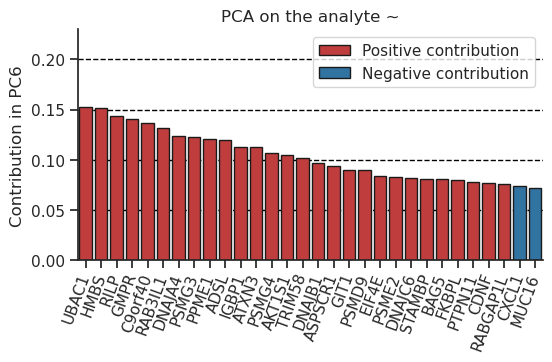

In [14]:
tempDF1 = pcaDF_axes
tempDF2 = pca_varDF
tempDF3 = IDdata.set_index('OlinkID')
topX = 259#nPCs
topY = 30#nFeatures
ymax = tempDF1.iloc[:topX].max(axis=0).max() * 1.2
fig_title = 'PCA on the analyte ~'

#Prepare projections in topX PCs
# tempDF = tempDF1.iloc[:topX]
tempDF = tempDF1.loc[selected]
##Add explained variance to the PC names
tempS = tempDF2['PClabel'].loc[selected]
tempDF.index = tempDF.index.map(tempS)
##Add analyte labels
tempS = tempDF3['Symbol']
tempDF_T = tempDF.T
tempDF = pd.merge(tempDF_T, tempS, left_index=True, right_index=True, how='left')
# tempDF = tempDF.reset_index().set_index(['OlinkID', 'Assay'])
tempDF = tempDF.reset_index().set_index(['Symbol'])
# display(tempDF)
tempDF = tempDF.drop(columns = ['index'])
tempDF1 = tempDF#Update

display(tempDF1)

#Visualize feature contribution to each PC axis
for pc_n in tempDF1.columns:
    tempDF = tempDF1.copy()
    #Take topY features
    tempDF[pc_n+'_abs'] = abs(tempDF[pc_n])
    tempDF = tempDF.sort_values(by=pc_n+'_abs', ascending=False)
    tempDF = tempDF.iloc[:topY]
    print('Top '+str(topY)+' contributors in', pc_n)
    display(tempDF)
    
    #Category
    tempL = []
    for row_n in tempDF.index:
        if tempDF.loc[row_n, pc_n]>0:
            tempL.append('Positive contribution')
        elif tempDF.loc[row_n, pc_n]<0:
            tempL.append('Negative contribution')
        else:#Just in case
            tempL.append('No cotribution')
    tempDF['Contribution'] = tempL
    
    #Visualization
    tempDF = tempDF.reset_index()
    tempD = {'Positive contribution':'tab:red', 'Negative contribution':'tab:blue'}
    sns.set(style='ticks', font='DejaVu Sans', context='notebook')
    plt.figure(figsize=(topY/5, 3))
    p = sns.barplot(data=tempDF, y=pc_n+'_abs', x='Symbol',
                    hue='Contribution', palette=tempD, dodge=False, edgecolor='k')
    p.set(ylim=(0, ymax))
    p.grid(axis='y', linestyle='--', color='black')
    sns.despine()
    plt.xticks(rotation=70, horizontalalignment='right', verticalalignment='center', rotation_mode='anchor')
    plt.xlabel('')
    plt.ylabel('Contribution in '+pc_n)
    plt.title(fig_title)
    plt.legend(loc='upper right')

    fig = plt.gcf()
    filename = "./ExportData/PrincipalAxes_" + pc_n + ".svg"
    fig.savefig(filename,dpi = 300, bbox_inches="tight",transparent=True)
    
    plt.show()
    plt.close(fig)



,PC21,PC1,PC4,PC7,PC5,PC10,PC6
Symbol,,,,,,,
AMP1*,-0.011586,0.018141,-0.014467,-0.015036,-0.057522,0.087969,-0.024905
INC1*,0.014927,-0.004737,0.011010,0.005368,-0.016070,-0.055952,0.030074
CCND1,0.023978,0.021761,-0.004627,-0.019611,-0.049044,0.035136,-0.008352
CENPS,-0.015819,0.006063,-0.013568,0.007379,-0.018675,0.008606,0.006722
ERG,-0.061130,0.041839,-0.027955,0.031332,-0.022332,-0.005652,-0.018276
...,...,...,...,...,...,...,...
PTPRK,0.041745,0.023250,0.004326,-0.014785,-0.036025,0.047343,-0.010078
DNAJB1,-0.018825,0.040980,0.001004,0.018674,-0.013407,0.036586,0.097203
PPME1,-0.006872,0.034978,-0.003687,0.046334,-0.005913,0.075362,0.120998


Top 50 contributors in PC21


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC21_abs
Symbol,,,,,,,,
CTRL,0.130882,0.009735,0.031935,0.055914,0.000172,0.022106,-0.023938,0.130882
SERPINI2,0.127397,0.005975,0.036571,0.037419,-0.015934,0.018984,-0.007040,0.127397
GP2,0.116463,0.013856,0.032943,0.065155,0.014950,0.011156,-0.012733,0.116463
LCK,0.114799,0.027322,-0.026734,-0.080798,-0.058129,0.005313,0.019469,0.114799
CTRC,0.112067,0.002825,0.023572,0.034674,-0.035220,0.011188,-0.002722,0.112067
MMP12,0.103359,0.033823,-0.001044,-0.021524,0.043397,0.003149,-0.035443,0.103359
KRT19,0.100874,0.033610,0.014336,0.048021,0.044295,0.076486,-0.060570,0.100874
PNLIPRP1,0.099647,0.013638,0.035200,0.015654,0.023274,0.015840,0.000497,0.099647
IFIT3,-0.099191,0.037037,-0.020663,-0.005801,-0.021852,-0.080444,-0.036380,0.099191


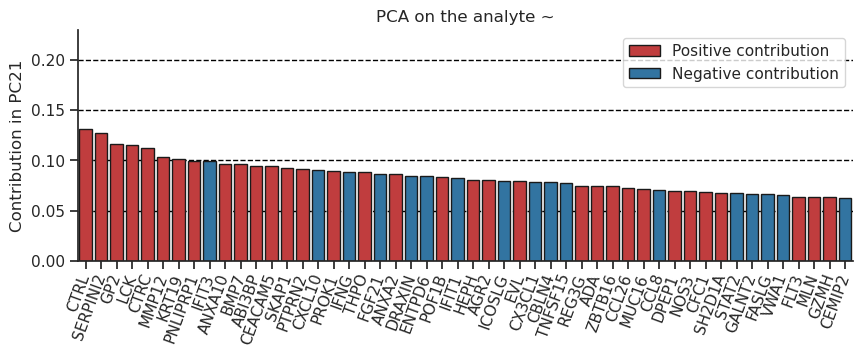

Top 50 contributors in PC1


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC1_abs
Symbol,,,,,,,,
PAG1,0.011360,0.061442,-0.012053,0.022850,0.014229,-0.017938,-0.020515,0.061442
RC3H1,0.020314,0.060743,0.027652,-0.002012,0.004524,-0.007177,-0.014082,0.060743
TXLNA,0.040927,0.060689,0.014615,-0.021164,-0.009806,-0.016683,0.032458,0.060689
MAD1L1,0.010535,0.060090,0.028914,0.021029,0.042565,0.000247,-0.033787,0.060090
MAP2K1,-0.006116,0.059407,-0.007628,0.029909,0.014956,-0.009947,0.018928,0.059407
POLR2F,0.009300,0.059211,-0.002443,0.012247,0.015757,0.017328,-0.007971,0.059211
USO1,-0.006515,0.059013,0.023324,0.018069,-0.014995,-0.003480,0.018948,0.059013
PRKAR2A,-0.008726,0.058787,0.046720,0.012332,-0.002926,-0.014325,0.019122,0.058787
CASP8,-0.001832,0.058624,-0.015682,0.008898,0.007541,0.009019,0.012053,0.058624


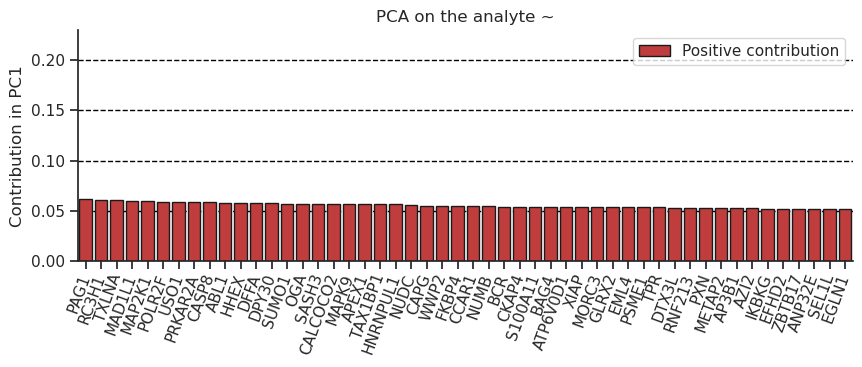

Top 50 contributors in PC4


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC4_abs
Symbol,,,,,,,,
PDZK1,-0.037252,0.040046,0.103831,-0.018275,-0.032622,-0.031703,0.008182,0.103831
BAIAP2,0.061297,0.034036,0.100999,-0.019314,-0.027263,-0.006484,-0.011034,0.100999
SULT2A1,-0.000198,0.035899,0.099465,-0.047157,-0.025651,-0.013823,0.004594,0.099465
ACAA1,0.016752,0.035255,0.099044,-0.005055,-0.037796,-0.059854,0.011695,0.099044
SPATA2L,0.013949,0.030014,0.098128,-0.019024,-0.039193,-0.047193,0.012684,0.098128
ACE2,-0.030890,0.037926,0.097755,0.006000,-0.003638,-0.001273,0.004920,0.097755
GFER,-0.005059,0.041326,0.097411,-0.031280,-0.025929,-0.039310,0.007493,0.097411
HAO1,0.011270,0.026835,0.093226,-0.030666,-0.053386,-0.043731,0.014169,0.093226
KHK,-0.003397,0.029567,0.092921,-0.064530,-0.057108,-0.037599,0.018690,0.092921


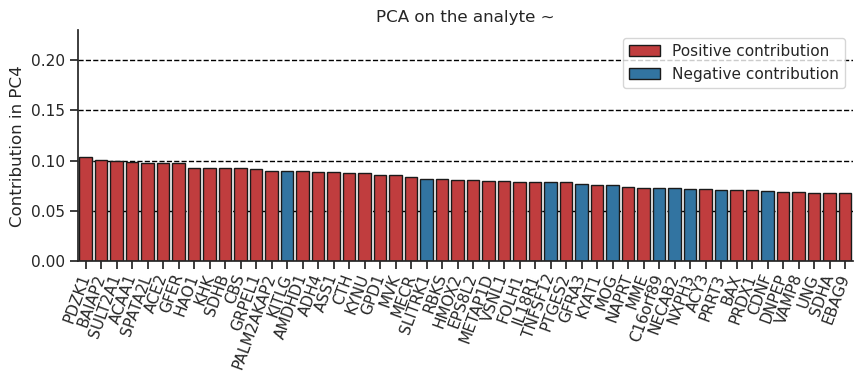

Top 50 contributors in PC7


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC7_abs
Symbol,,,,,,,,
MS4A1,0.030863,0.012027,-0.005891,-0.104177,-0.061747,0.001376,-0.015191,0.104177
FURIN,-0.013547,0.024370,0.009313,-0.102321,-0.036944,0.045169,-0.024999,0.102321
HBEGF,0.013015,0.009697,0.008611,-0.099379,-0.013257,0.103344,-0.031302,0.099379
IFNLR1,0.003543,0.028544,0.000201,-0.098871,-0.027391,0.023372,-0.015119,0.098871
BACE1,0.004440,-0.000599,-0.051780,0.091711,-0.104687,-0.004121,-0.003629,0.091711
SIT1,0.058159,0.020864,0.011803,-0.091250,-0.072778,-0.017933,0.005705,0.091250
BCAN,0.006055,0.001604,-0.058145,0.088370,-0.057374,0.000023,-0.016025,0.088370
PGLYRP3,0.032332,0.001282,-0.023137,-0.086696,-0.018951,0.013415,0.060675,0.086696
NPPC,0.043480,0.013365,-0.037345,-0.086695,0.005004,0.052675,0.029202,0.086695


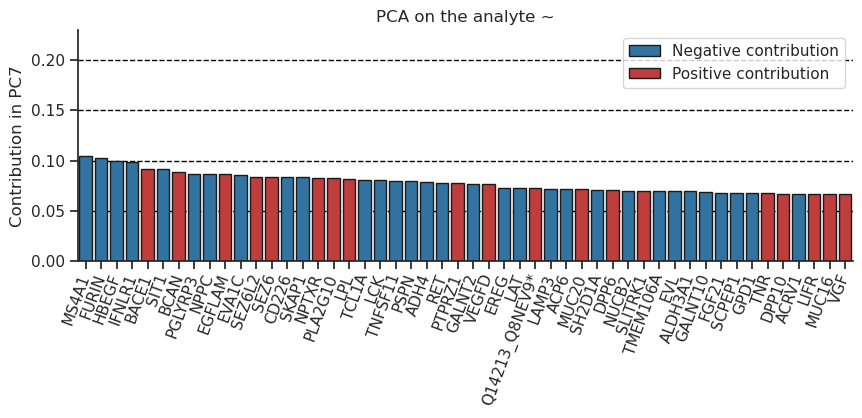

Top 50 contributors in PC5


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC5_abs
Symbol,,,,,,,,
ROBO2,0.015712,-0.001564,-0.058648,0.038611,-0.104994,-0.009796,-0.010759,0.104994
BACE1,0.004440,-0.000599,-0.051780,0.091711,-0.104687,-0.004121,-0.003629,0.104687
ENPP6,0.013627,-0.015691,-0.046354,0.045779,-0.103495,-0.026507,0.007445,0.103495
C1QL2,-0.007343,-0.005063,-0.025471,-0.027635,-0.102179,-0.003062,-0.035217,0.102179
RECK,-0.037800,0.005157,-0.035175,0.049903,-0.100884,-0.010694,-0.035610,0.100884
CD22,-0.007100,0.009903,-0.008951,-0.057418,-0.094818,-0.008491,-0.026342,0.094818
NELL1,0.036296,-0.000533,0.002500,0.037441,-0.093481,0.006015,-0.005447,0.093481
PTPRZ1,-0.003174,0.002189,-0.041059,0.077294,-0.091570,-0.050472,-0.017581,0.091570
NPHS1,0.017770,0.002013,0.000742,-0.021029,-0.089904,0.019163,-0.021944,0.089904


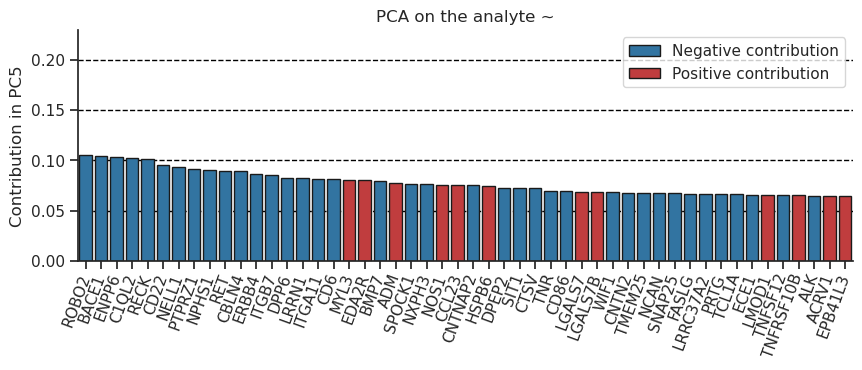

Top 50 contributors in PC10


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC10_abs
Symbol,,,,,,,,
IL7,-0.005077,0.014038,0.011883,-0.038208,-0.011986,0.116065,-0.046795,0.116065
ADAM12,0.008934,0.032563,-0.000474,-0.004677,0.032332,0.109990,-0.052740,0.109990
PAEP,0.016104,0.015588,0.008359,0.034390,0.030263,0.105539,-0.055555,0.105539
HBEGF,0.013015,0.009697,0.008611,-0.099379,-0.013257,0.103344,-0.031302,0.103344
COL24A1,0.045090,0.019244,-0.024818,0.004406,-0.013746,0.097779,-0.068056,0.097779
ITGAV,-0.059654,-0.010738,-0.022434,0.022798,-0.058218,-0.092301,0.029438,0.092301
LAT,-0.018785,0.017084,0.003037,-0.072902,-0.006321,0.089896,-0.005588,0.089896
AMP1*,-0.011586,0.018141,-0.014467,-0.015036,-0.057522,0.087969,-0.024905,0.087969
AMIGO2,0.011649,0.035418,0.016179,0.011982,-0.046208,0.087239,-0.054350,0.087239


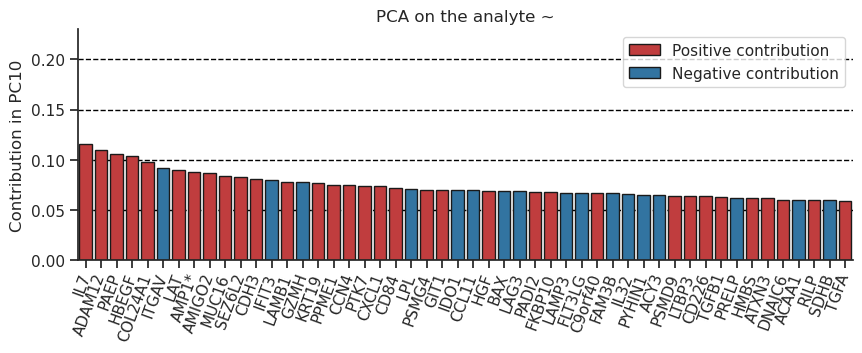

Top 50 contributors in PC6


,PC21,PC1,PC4,PC7,PC5,PC10,PC6,PC6_abs
Symbol,,,,,,,,
UBAC1,0.009259,0.025633,-0.002213,0.056372,-0.009510,0.040382,0.152999,0.152999
HMBS,-0.004925,0.023815,0.011633,0.040976,-0.020890,0.062321,0.151246,0.151246
RILP,-0.012579,0.030322,0.013457,0.054598,-0.022945,0.059772,0.143551,0.143551
GMPR,-0.005595,0.016991,-0.007202,0.034976,-0.023610,0.049324,0.140720,0.140720
C9orf40,-0.031078,0.018382,-0.003735,0.032031,-0.036460,0.066745,0.136713,0.136713
RAB3IL1,-0.020238,0.030289,0.021567,0.046278,-0.010985,0.057842,0.131640,0.131640
DNAJA4,-0.002299,0.026772,-0.012797,0.047679,-0.005036,0.036919,0.123608,0.123608
PSMG3,-0.019297,0.036070,0.002995,0.025366,-0.005236,0.056010,0.123076,0.123076
PPME1,-0.006872,0.034978,-0.003687,0.046334,-0.005913,0.075362,0.120998,0.120998


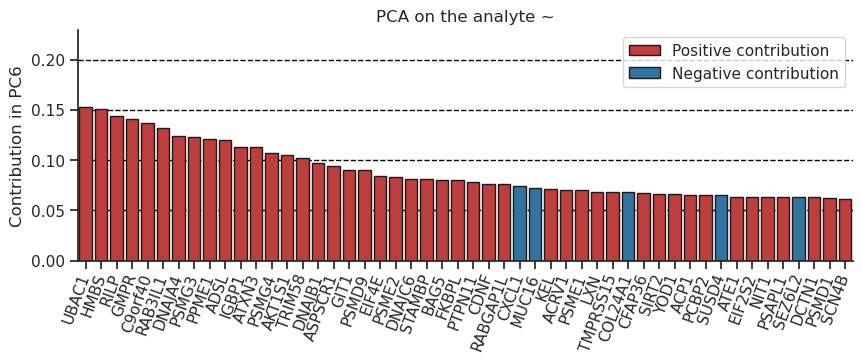

In [15]:
tempDF1 = pcaDF_axes
tempDF2 = pca_varDF
tempDF3 = IDdata.set_index('OlinkID')
topX = 259#nPCs
topY = 50#nFeatures
ymax = tempDF1.iloc[:topX].max(axis=0).max() * 1.2
fig_title = 'PCA on the analyte ~'

#Prepare projections in topX PCs
# tempDF = tempDF1.iloc[:topX]
tempDF = tempDF1.loc[selected]
##Add explained variance to the PC names
tempS = tempDF2['PClabel'].loc[selected]
tempDF.index = tempDF.index.map(tempS)
##Add analyte labels
tempS = tempDF3['Symbol']
tempDF_T = tempDF.T
tempDF = pd.merge(tempDF_T, tempS, left_index=True, right_index=True, how='left')
# tempDF = tempDF.reset_index().set_index(['OlinkID', 'Assay'])
tempDF = tempDF.reset_index().set_index(['Symbol'])
# display(tempDF)
tempDF = tempDF.drop(columns = ['index'])
tempDF1 = tempDF#Update

display(tempDF1)

#Visualize feature contribution to each PC axis
for pc_n in tempDF1.columns:
    tempDF = tempDF1.copy()
    #Take topY features
    tempDF[pc_n+'_abs'] = abs(tempDF[pc_n])
    tempDF = tempDF.sort_values(by=pc_n+'_abs', ascending=False)
    tempDF = tempDF.iloc[:topY]
    print('Top '+str(topY)+' contributors in', pc_n)
    display(tempDF)
    
    #Category
    tempL = []
    for row_n in tempDF.index:
        if tempDF.loc[row_n, pc_n]>0:
            tempL.append('Positive contribution')
        elif tempDF.loc[row_n, pc_n]<0:
            tempL.append('Negative contribution')
        else:#Just in case
            tempL.append('No cotribution')
    tempDF['Contribution'] = tempL
    
    #Visualization
    tempDF = tempDF.reset_index()
    tempD = {'Positive contribution':'tab:red', 'Negative contribution':'tab:blue'}
    sns.set(style='ticks', font='DejaVu Sans', context='notebook')
    plt.figure(figsize=(topY/5, 3))
    p = sns.barplot(data=tempDF, y=pc_n+'_abs', x='Symbol',
                    hue='Contribution', palette=tempD, dodge=False, edgecolor='k')
    p.set(ylim=(0, ymax))
    p.grid(axis='y', linestyle='--', color='black')
    sns.despine()
    plt.xticks(rotation=70, horizontalalignment='right', verticalalignment='center', rotation_mode='anchor')
    plt.xlabel('')
    plt.ylabel('Contribution in '+pc_n)
    plt.title(fig_title)
    plt.legend(loc='upper right')

    fig = plt.gcf()
    filename = "./ExportData/PrincipalAxes_" + pc_n + ".svg"
    fig.savefig(filename,dpi = 300, bbox_inches="tight",transparent=True)
    
    plt.show()
    plt.close(fig)

